# Directional Couplers and Coupled Mode Theory

How does evanescent coupling between two nearby waveguides lead to periodic power transfer, and how can the coupling strength be related to the propagation constants of the coupled mode?

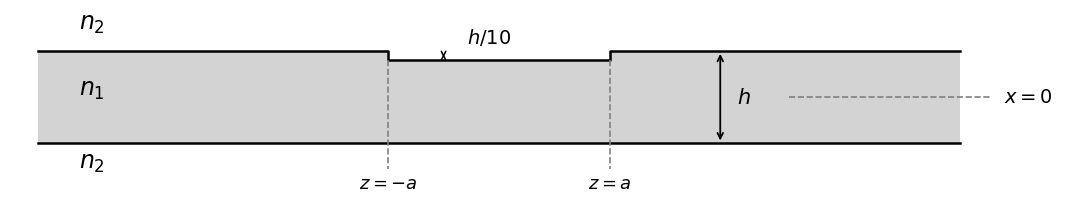

In [3]:

import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# Geometry parameters (normalized units)
h = 1.0
a = 1.2
L = 5.0

top = h / 2
bottom = -h / 2
notch_bottom = top - h / 10

fig, ax = plt.subplots(figsize=(11, 5))

# Core geometry (n1)
vertices = [
    (-L, bottom),
    ( L, bottom),
    ( L, top),
    ( a, top),
    ( a, notch_bottom),
    (-a, notch_bottom),
    (-a, top),
    (-L, top)
]

core = Polygon(
    vertices,
    closed=True,
    facecolor="lightgray",
    edgecolor="none"
)
ax.add_patch(core)

# Waveguide interfaces
z_top = [-L, -a, -a, a, a, L]
x_top = [top, top, notch_bottom,
         notch_bottom, top, top]

ax.plot(z_top, x_top, color="black", lw=1.8)
ax.plot([-L, L], [bottom, bottom],
        color="black", lw=1.8)

# Vertical dashed lines: z = -a, z = a
for z in [-a, a]:
    ax.plot(
        [z, z],
        [notch_bottom, bottom - 0.28],
        ls="--", color="gray", lw=1.2
    )

ax.text(-a, bottom - 0.34, r"$z=-a$",
        ha="center", va="top", fontsize=13)
ax.text(a, bottom - 0.34, r"$z=a$",
        ha="center", va="top", fontsize=13)

# Thickness h
ax.annotate(
    "",
    xy=(2.4, top),
    xytext=(2.4, bottom),
    arrowprops=dict(arrowstyle="<->", lw=1.3)
)
ax.text(2.58, 0, r"$h$",
        va="center", fontsize=15)

# Notch depth h/10
ax.annotate(
    "",
    xy=(-0.6, top),
    xytext=(-0.6, notch_bottom),
    arrowprops=dict(arrowstyle="<->", lw=1.1,
                    mutation_scale=8)
)
ax.text(-0.35, top + 0.08, r"$h/10$",
        fontsize=14, ha="left")

# Refractive-index labels
ax.text(-4.55, 0.73, r"$n_2$", fontsize=17)
ax.text(-4.55, 0.02, r"$n_1$", fontsize=17)
ax.text(-4.55, -0.77, r"$n_2$", fontsize=17)

# Center reference line: x = 0
ax.plot(
    [3.15, L + 0.35], [0, 0],
    ls="--", color="gray", lw=1.2
)
ax.text(L + 0.48, 0, r"$x=0$",
        va="center", fontsize=14)

# Formatting
ax.set_xlim(-5.3, 6.3)
ax.set_ylim(-1.05, 0.95)
ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()
plt.show()

# Optional: save figure
# fig.savefig("waveguide_perturbation.png",
#             dpi=300, bbox_inches="tight")


## From Independent Modes to Coupled Modes

From this point onward, $j$ denotes the imaginary unit.

Assume that only $\mathrm{TE}$ modes are carried, the electric field of the eigenmodes of this structure satisfies the wave equation,
$$\nabla ^2 E_y(x, z, t) = \epsilon\mu\frac{\partial^2 E_y(x, z, t)}{\partial t^2}$$

If $\epsilon$, $\mu$ are time-invariant quantuties,
$$E_{yi}(x, z, t) = \frac{1}{2}A_i\varepsilon_{yi}(x)e^{-j(\beta_iz-\omega t)} + c.c$$

$A_i$: amplitude for mode $i$

$\varepsilon_{yi}(x)$: Normalized amplitude distribution for mode $i$, given by for the astmmetric slab waveguide

If there are no perturbations in the waveguide, the modes will be completely independent from one another. However, any deviation from this well-defined waveguide structure perturbs the modes and couples energy between them. For this reason, we must describe the perturbation in terms of a distributed polarization source, $P_\text{pert}$.

Why is polarization the preferred method for solving these problems? Let's recall: `03_conductors_currents_and_dielectrics`

$$D = \epsilon E = \epsilon_0 E + P$$

defined through the expression,
$$D = \epsilon E + P_\text{pert}$$

$$\nabla^2E_y =  \epsilon\mu \frac{\partial^2E_y}{\partial t^2} + \mu\frac{\partial^2P\text{pert}}{\partial t^2}$$

To solve this equation, we use standard perturbation theory techniques. Since the eigenmodes of the waveguide form a complete set, any continuous electric field distribution, $E(x)$, can be described in terms of the modes of the system

$$E(x) = \frac{1}{2} \sum_i A^+_i\varepsilon_{i}(x)e^{-j(\beta_iz-\omega t)} + \frac{1}{2} \sum_i A^-_i\varepsilon_{i}(x)e^{j(\beta_iz+\omega t)} + \frac{1}{2}\int_{k_0n_s}^{k_0n_f}A(\beta, z)\varepsilon_\beta(x)e^{-j(\beta z-\omega t)}d\beta + c.c$$

$$\mu \frac{\partial^2}{\partial t^2}P_\text{pert} = \frac{1}{2}\sum_i \left[ \frac{\partial^2 A_i^+}{\partial z^2} - 2j\beta_i\frac{\partial A_i^+}{\partial z} \right] \varepsilon_i(x)e^{-j(\beta_iz-\omega t)} + \frac{1}{2}\sum_i \left[ \frac{\partial^2 A_i^-}{\partial z^2} + 2j\beta_i\frac{\partial A_i^-}{\partial z} \right] \varepsilon_i(x)e^{j(\beta_iz+\omega t)} + c.c$$

If we assume that the perturbation causes **slow variations** in the amplitude, then the second derivative terms are negligible.
$$\mu \frac{\partial^2}{\partial t^2}P_\text{pert} = \frac{1}{2}\sum_i \left[ - 2j\beta_i\frac{\partial A_i^+}{\partial z} \right] \varepsilon_i(x)e^{-j(\beta_iz-\omega t)} + \frac{1}{2}\sum_i \left[ + 2j\beta_i\frac{\partial A_i^-}{\partial z} \right] \varepsilon_i(x)e^{j(\beta_iz+\omega t)} + c.c$$

We can simplify the equation using mode orthogonality. The normalized eigenfunctions to the wave equation, satisfy
$$\frac{1}{2} \int\varepsilon_i(x) \times \mathcal{H}_j(x) dA = \delta_{ij}$$

Assuming that we are using a $\mathrm{TE}$ mode, Maxwell's equations can be used to express $\mathcal{H}_x$ in terms of $\varepsilon_y$ for normalized field 
$$\int_{-\infty}^\infty \varepsilon_i(x)\varepsilon_j(x) dx = \frac{2\omega\mu}{\beta_i}\delta_{ij} $$

Using mode orthogonality,
$$\frac{\partial A_j^-}{\partial z}e^{j(\beta z + \omega t)} - \frac{\partial A_j^+}{\partial z}e^{-j(\beta z - \omega t)} + c.c = \frac{-j}{2\omega}\frac{\partial ^2}{\partial t^2}\int_{-\infty}^{\infty}P_\text{pert}(x)\cdot\varepsilon_j(x) dx$$ 

## Coupled-Mode Equation

From this point onward, $i$ denotes the imaginary unit.

### Coupling due to a dielectric perturbation

General perturbation example: a dielectric perturbation couples otherwise independent eigenmodes. To determine the coupling, we must describe the perturbation term.
$$P_\text{pert}(x) = \Delta\epsilon E_1$$

$$P_\text{pert}(x) = \epsilon_0(n_2^2 - n_1^2)\left[\frac{1}{2}A^{+}\varepsilon(x)e^{-i(\beta z - \omega t)}\right] + c.c \quad \text{for $0.4\,h < x < 0.5\,h, \quad -a < z < a$}$$
$$P_\text{pert}(x) = 0$$

only in the nothch region. The amplitude equation of motion,
$$\frac{\partial A^{-}}{\partial z}e^{i(\beta z + \omega t)} - \frac{\partial A^{+}}{\partial z}e^{-i(\beta z - \omega t)} + c.c = \int_{0.4h}^{0.5h}P_\text{pert}\varepsilon_y(x) dx$$

$$\frac{\partial A^{-}}{\partial z}e^{i(\beta z + \omega t)} - \frac{\partial A^{+}}{\partial z}e^{-i(\beta z - \omega t)} + c.c = i \mathcal{K}\left(A^{+}e^{-i(\beta z - \omega t)}\right) + c.c$$

$\mathcal{K}$ is the coupling constant; determined in the pertubation region.
$$\mathcal{K} = \frac{\omega\epsilon_0(n_2^2-n_1^2)}{4}\int_{0.4h}^{0.5h}|C|^2\left(\frac{\cos\kappa x}{\cos\kappa h/2}\right)^2 dx \quad \text{for -a < z < a}$$

$$\mathcal{K} = 0 \quad \text{elsewhere}$$

Let's multiply $e^{i(\beta z - \omega t)}$,
$$\frac{\partial A^{-}}{\partial z}e^{2i\beta z} - \frac{\partial A^{+}}{\partial z} + c.c =  i \mathcal{K}A^{+}$$

Simplified quation of motion, 
$$-\frac{dA^{+}}{dz} = i\mathcal{K}A^{+}$$

and apply the initial conditon $A_0 = A(-a)$,
$$A^{+}(z) = A^{+}(-a)e^{-i\mathcal{K}z}$$

The forward wave in the region of the perturbation:
$$E(z) = \frac{A^{+}(-a)}{2}e^{-i(\beta + \mathcal{K})z} \quad \text{for $-a < z < a$}$$

$$A^{-}(-a) = \frac{-i\mathcal{K}A^{+}}{\beta}\sin(2\beta a)$$

The maximum reflection occurs when
$$a = \frac{(q + 1/2)\pi}{2\beta} \quad q \in \mathbb{Z}$$

Generally, maximum coupling will occur between a forward and backward wave when the spatial frequency of the perturbation is approximately $2\beta$

### Intermode Coupling

The epcific form for the two spatial modes:
$$E_a(x, t) = \left[(A/2)\varepsilon_a(x)e^{-i(\beta_a z - \omega t)} + c.c \right]$$
$$E_b(x, t) = \left[(B/2)\varepsilon_b(x)e^{-i(\beta_b z - \omega t)} + c.c \right]$$

The perturbation term arises from the presence of the electric field from mode $A$, in the dielectric motch,
$$P_\text{pert} = \epsilon_0(n_2^2 - n_1^2)E_a(x, t)$$

Multiplying $e^{i(\beta_b z-\omega t)}$,
$$-\frac{\partial B^{+}}{\partial z} + \frac{\partial B^{-}}{\partial z}e^{2i\beta_bz} = i\mathcal{K}A^{+}e^{-i(\beta_a - \beta_b)z}$$

Solving the integral,
$$B^{+}(a) = -i\mathcal{K}A^{+}\int_{-a}^{a}e^{-i(\beta_a - \beta_b)z}dz$$
$$B^{+}(a) = \frac{-2i\mathcal{K}A^{+}}{(\beta_a - \beta_b)}\sin\left[(\beta_a - \beta_b)a\right]$$

The two modes have dramatically different values of $\beta$; the overall power coupling will be weak due to the inverse square dependence on the difference in the propagation constant. **Only** closely related in beta will **couple significantly**. 

The coupling depends directly on the value of the coupling constant $\mathcal{K}$

As before, the coupling is periodic. Energy flows back and forth between the two modes in the perturbation region, and the ultimate coupling depends on the termination point of the perturbation.

### Phase matching
$$B^{+}(a) \approx \frac{\sin[(\beta_a - \beta_b)a]}{\beta_a - \beta_b}$$
So,
$$\Delta\beta = \beta_a - \beta_b$$

$$\Delta\beta = 0 \Rightarrow \text{constructive accumulation, strongest coupling}$$
$$|\Delta\beta|L \gg 1 \Rightarrow \text{phase cancellation}$$

The coupling maximum appears when
$$\beta_a = \beta_b + q\pi/2a \quad (q \,\, \text{odd})$$

When the spatial period of the perturbation makes up the difference between the two propagation constants, there will be enhanced coupling.

### Reciprocity

$$\frac{dA}{dz} = i\mathcal{K_{ab}}Be^{-i(\beta_a - \beta_b)z}$$
$$\frac{dB}{dz} = i\mathcal{K^{*}_{ba}}Ae^{i(\beta_a - \beta_b)z}$$

Where $A$ and $B$ are the amplitudes of two modes, and $\mathcal{K}$ is a coupling constant.

The conservation of energy is:
$$\frac{d}{dz}(|A|^2 + |B|^2) = 0$$

Furthermore,

$$
\mathbf{a}(z) = \begin{bmatrix}
a_1(z) \\
a_2(z)
\end{bmatrix}
$$
$$\frac{d}{dz} \mathbf{a} = 
-i
\begin{bmatrix}
\beta_1 & \kappa \\
\kappa^{*} & \beta_2
\end{bmatrix}
\mathbf{a}
$$

$a_1(z)$ and $a_2(z)$ denote the complex modal coefficients in the local waveguide basis. In the numerical two-mode model below, $\kappa$ denotes the inter-waveguide coupling coefficient, distinct from the transverse wave number used above.

Therefore, the governing equation is, 
$$i\frac{d\mathbf{a}}{dz} = H\mathbf{a}$$

## Degenerate Coupling and Periodic Power Exchange

Energy can tunnel from one guide to the other through interaction between their evanescent tails.
Let's assume that initially only one waveguide carries energy in the device. The polarization perturbation arises from the presence of an external electric field in the waveguide, rather than from a dielectric defect.

In the cores of the uncoupled waveguides, both have the same transverse and longitudinal wavevectors. Outside the core, the field decays exponentially. 

The polarization perturbation in waveguide B arises from the presence of the evanescent tail of mode $A$. Because of phase matching, backward coupling is strongly phase-mismatched and therefore neglected.

By symmetry,
$$-\frac{\partial A}{\partial z}e^{-i(\beta z - \omega t)} = i\mathcal{K}Be^{-i(\beta z - \omega t)}$$

For two identical waveguides in a reciprocal symmetric system, the mutual coupling coefficients are equal; the formulas reduce to
$$\frac{\partial A}{\partial z} = -i\mathcal{K}B$$
$$\frac{\partial B}{\partial z} = -i\mathcal{K}A$$

Taking the derivative of the first equation and plugging it into the second equation reduces these two first-order differential equations into an uncoupled second-order equation 
$$\frac{\partial^2 A}{\partial z^2} = -\mathcal{K}^2A$$

If initial condition is $A(0) = 1$ and $B(0) = 0$,
$$A(z) = \cos(\mathcal{K}z)$$
$$B(z) = -i\sin(\mathcal{K}z)$$

Therefore,
$$P_A(z) = |A|^2 = \cos^2(\mathcal{K}z)$$
$$P_B(z) = |B|^2 = \sin^2(\mathcal{K}z)$$

So,
$$P_A + P_B = 1$$

and the first complete-transfer length,
$$L_c = \frac{\pi}{2|\mathcal{K}|}$$


The coupling redistributes optical power between the two modal amplitudes while conserving the total power. The energy transfer from one waveguide to the other will continue until the driving waveguide is totally depleted of energy. At that point, the driven waveguide suddenly becomes the source perturbing the original waveguide, and energy flows in the opposite direction; during this phase, no energy is transferred in the backward-wave direction.

The length of the interaction region determines the exact value of coupling. If the coupling distance $z_0$ is set to be
$$z_0 = \frac{\pi}{2\mathcal{K}} + \frac{q\pi}{\mathcal{K}}, \quad q \in \mathbb{Z}$$

Other lengths yield values between $0\,\%$ and $100\,\%$, allowing the designer to make couplers of any desired strength. That comes with a price.

## Connection to the Numerical Model: Supermode Interpretation

When multiple individual waveguides are placed close enough together for their electromagnetic field to overlap and couple.

Let's treat each $\mathrm{TE_0}$ to one whole eigenmodes,

$$\psi_{+}(x), \quad \psi_{-}(x)$$

symmetric and antisymmetric supermodes, respectively.

Let's define the propagation constants, respectively,
$$\beta_{+}, \quad \beta_{-}$$

If the waveguides are identical, 
$$
H = \begin{bmatrix}
\beta_0 & \kappa \\
\kappa & \beta_0
\end{bmatrix}$$

For identical waveguides with a real coupling coefficient $\kappa$.

The eigenvectors are
$$
\frac{1}{\sqrt{2}}\begin{bmatrix}
1\\
1
\end{bmatrix}, \quad
\frac{1}{\sqrt{2}}\begin{bmatrix}
1\\
-1
\end{bmatrix}
$$

eigenvalues are,
$$\beta_{+} = \beta_0 + \kappa, \quad \beta_{-} = \beta_0 - \kappa$$

Therefore,
$$\kappa \approx \frac{\beta_{+} - \beta_{-}}{2}$$

then,

$$L_c = \frac{\pi}{|\beta_{+} - \beta_{-}|}$$

## Optional connection — Mode Matching Between Different Waveguides

Consider of coupling two single mode slab waveguides, $\mathrm{TE_0}$

Let's define the normalized input spatial mode as $\varepsilon_i(x)$, the normalized transmitted node as $\varepsilon_t(x)$, and radiation modes as $\varepsilon_\beta(x)$ the fields must satisfy equation

$$\varepsilon_i(x) + r\varepsilon_i(x) + \int_0^\infty r(\beta)\varepsilon_\beta(x)d\beta = t\varepsilon_t(x) + \int_0^\infty t(\beta)\varepsilon_\beta(x)d\beta$$

$$\mathcal{H}_i(x) + r\mathcal{H}_i(x) - \int_0^\infty r(\beta)\mathcal{H}_\beta(x)d\beta = t\mathcal{H}_t(x) + \int_0^\infty t(\beta)\mathcal{H}_\beta(x)d\beta $$

$$\mathcal{H}_x = \frac{-i}{\omega\mu}\frac{\partial\varepsilon_y}{\partial z} = - \frac{\beta}{\omega\mu}\varepsilon_y$$

It is impossible to obtain an exact solution to $\varepsilon_i(x) + r\varepsilon_i(x) + \int_0^\infty r(\beta)\varepsilon_\beta(x)d\beta = t\varepsilon_t(x) + \int_0^\infty t(\beta)\varepsilon_\beta(x)d\beta$; we can make an approximate solution by assuming that the amount of energy scattering into radiation modes is negligible, which will be true when the incident field and waveguide mode are not too dissimilar.

$$t =\frac{2\beta_i\beta_t}{2\beta_i + \beta_t}\frac{1}{2\omega\mu}\int_{-\infty}^{\infty}\varepsilon_i(x)\varepsilon_t^{*}(x)dx$$
$$r = \frac{\beta_i - \beta_t}{\beta_i + \beta_t}$$
$r$ is very similar to the Fresnel reflection formula, when the wave is incident normal to the surface. Replace $\beta$ by $k_0n_{\text{eff}}$ in $r$ produces the Fresnel expression.

The power coupling efficiency is equal to the square of the amplitude coupling,
$$\eta = |t|^2$$

In [6]:
from src.verification import absolute_error, complex_error, relative_error, find_convergence_threshold
from src.waveguide import create_uniform_grid, slab_index_profile, second_derivative_matrix, slab_waveguide_operator, solve_eigenmodes, select_guided_modes
from scipy.linalg import eigh
from scipy.optimize import brentq
from scipy.linalg import expm

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import math

kappa = 1.0

COLORS = {
    "numerical": "#1F5A94",
    "numerical_alt": "#4C78A8",
    
    "analytical": "#D97706",
    "approximation": "#2E7D32",
    
    "error": "#7E57C2",
    "error_alt": "#B07AA1",

    "reference": "#6B7280",
    "reference_alt": "#9CA3AF"
}

figure_dir = Path("../figures/10_directional_couplers_and_coupled_mode_theory")
figure_dir.mkdir(parents=True, exist_ok=True)

## Numerical Study - Case 1: Verification of the Two-Mode Coupled System

Can the coupled-mode equations reproduce periodic optical power transfer between two identical, lossless waveguides, and do independent numerical methods agree with the analytical solution?

### Governing Equations

$$\frac{d}{dz} \mathbf{a} = 
-i
\begin{bmatrix}
\beta_1 & \kappa \\
\kappa^{*} & \beta_2
\end{bmatrix}
\mathbf{a}
$$

$$
H = \begin{bmatrix}
\beta_0 & \kappa \\
\kappa & \beta_0
\end{bmatrix}$$

### Initial Conditions

- Identical Waveguides
- Propagation constants
$$\beta_1 = \beta_2 = \beta_0$$
- Coupling Coefficient: Real, Constant $\kappa > 0$
- Propagation loss: Neglected
- Excited modes: One guided mode per waveguide
- $$\mathrm{a}(0) = [1, 0]^T$$



### Analytic reference
Let's define $\mathbf{b}$ with
$$\mathbf{a}(z) = e^{-i\beta_0z}\mathbf{b}(z)$$

So,
$$i\frac{d\mathbf{b}}{dz} = \begin{bmatrix}
0 & \kappa \\
\kappa & 0
\end{bmatrix}\mathbf{b}$$

$$
\left\{
\begin{aligned}
b'_1 = -i\kappa b_2 \\
b'_2 = -i\kappa b_1
\end{aligned}
\right.
$$

then we can get:
$$b_1'' = -i\kappa b'_2 = (-i\kappa)^2b_1$$

When $y = b_1(z)$,
$$y'' + \kappa^2y = 0$$
$$y_1(z) = \cos\kappa z, \quad y_2(z) = \sin\kappa x$$

In general solution,
$$b_1(z) = C_1\cos\kappa z + C_2\sin\kappa z$$

From initial condition,
$$\mathbf{a}(0) = \mathbf{b}(0) = [1, 0]^T, \quad b_1(0) = 0$$

Therefore,
$$b_1(z) = \cos\kappa z \,\,\Rightarrow\,\, b_2(z) = -i\sin\kappa z$$

$$\mathbf{a}(z) = e^{-i\beta_0 z}\mathbf{b}(z)$$
$$\mathbf{a}(z) = e^{-i\beta_0 z}\begin{bmatrix}
\cos(\kappa z) \\
-i\sin(\kappa z)
\end{bmatrix}$$

$$|a_1(z)|^2 = \cos(\kappa z), \quad |a_2(z)|^2 = \sin(\kappa z)$$
$$|a_1(z)|^2 + |a_2(z)|^2 = 1$$

Furthermore,
Let's define $H'$
$$H' = \begin{bmatrix}
0 & \kappa \\
\kappa & 0
\end{bmatrix}$$

then,
$$e^{-iH'z} = \sum_{n=0}^{\infty} \frac{(-iH'z)^n}{n!} = I -iH'z - \frac{\kappa^2z^2}{2!}I + i\frac{\kappa^2H'z^3}{3!} \dots$$

$$I\cos(\kappa z) = I(1 -\frac{(\kappa z)^2}{2!} + \frac{(\kappa z)^4}{4!} - \dots)$$
$$-i\frac{H'}{\kappa}\sin(\kappa z) = -i\frac{H'}{\kappa}\left((\kappa z) - \frac{(\kappa z)^3}{3!} + \frac{(\kappa z)^5}{5!} - \dots\right)$$

So,
$$e^{-iH'z} = I\cos(\kappa z) -i\frac{H'}{\kappa}\sin(\kappa z)$$

we can use matrix exponential to $2 \times 2$ matrix:
$$e^{-iH'z} = \begin{bmatrix}
\cos(\kappa z) & -i\sin(\kappa z)\\
-i\sin(\kappa z) & \cos(\kappa z)
\end{bmatrix}$$

### Matrix exponential


In [9]:
H_prime = np.array([
    [0, kappa],
    [kappa, 0]
], dtype=complex)

b_0 = np.array([1, 0], dtype=complex)
L_c = np.pi / (2 * kappa)
z = L_c / 2


U = expm(-1j * H_prime * z)

b_z = U @ b_0

print("U(z) =", U)
print("b(z) =", b_z)

U(z) = [[0.70710678+0.j         0.        -0.70710678j]
 [0.        -0.70710678j 0.70710678+0.j        ]]
b(z) = [0.70710678+0.j         0.        -0.70710678j]


In [10]:
b_analytic = np.array([
    np.cos(kappa * z),
    -1j * np.sin(kappa * z)
])

error = np.linalg.norm(b_z - b_analytic)

print("Absolute error:", error)

Absolute error: 1.1102230246251565e-16


In [16]:
L_c = np.pi / (2 * kappa)
b_0 = np.array([1, 0], dtype=complex)

z = np.linspace(0, 2*L_c, 101)

H_prime = np.array([
    [0, kappa],
    [kappa, 0]
], dtype=complex)

U = np.array([expm(-1j * H_prime * z_i) for z_i in z ])

b_z = U @ b_0


b_analytic = np.column_stack((np.cos(kappa * z), -1j * np.sin(kappa * z)))
amplitude_error = np.linalg.norm(b_z - b_analytic, axis = 1)

power_conservation = np.abs(b_z[:, 0]) ** 2 + np.abs(b_z[:, 1]) ** 2
total_power = np.sum(np.abs(b_z)**2, axis=1)

max_amplitude_error = np.max(amplitude_error)
power_conservation_error = np.max(np.abs(total_power - 1))

print("Maximum amplitude error:", max_amplitude_error)
print("Power conservation error:", power_conservation_error)

Maximum amplitude error: 4.577566798522237e-16
Power conservation error: 5.551115123125783e-16
